['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 't

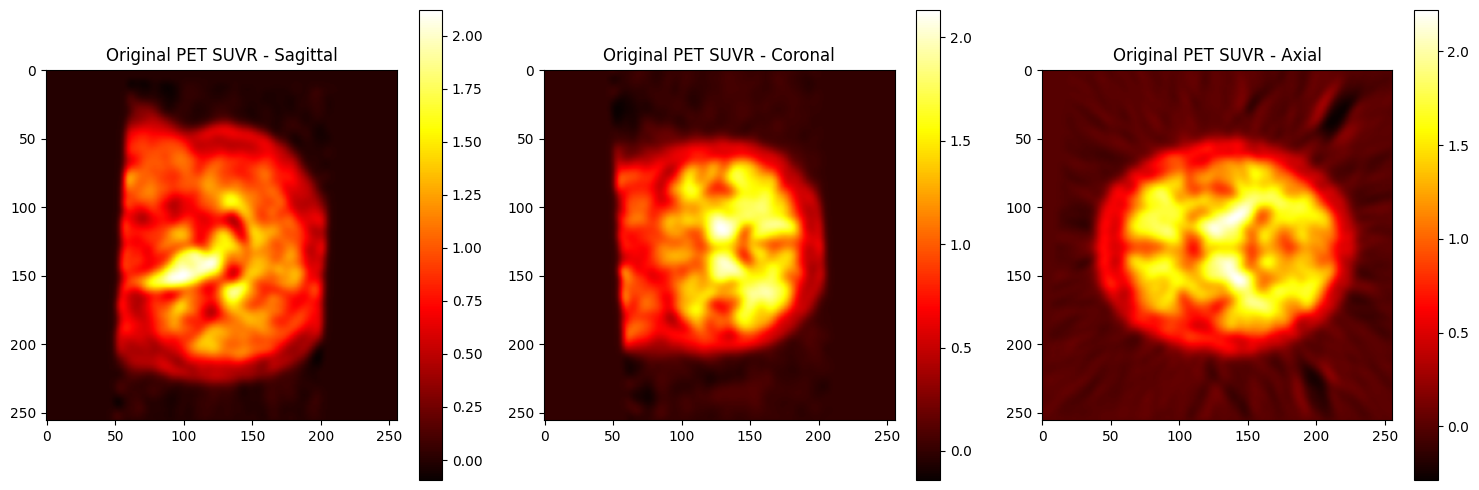

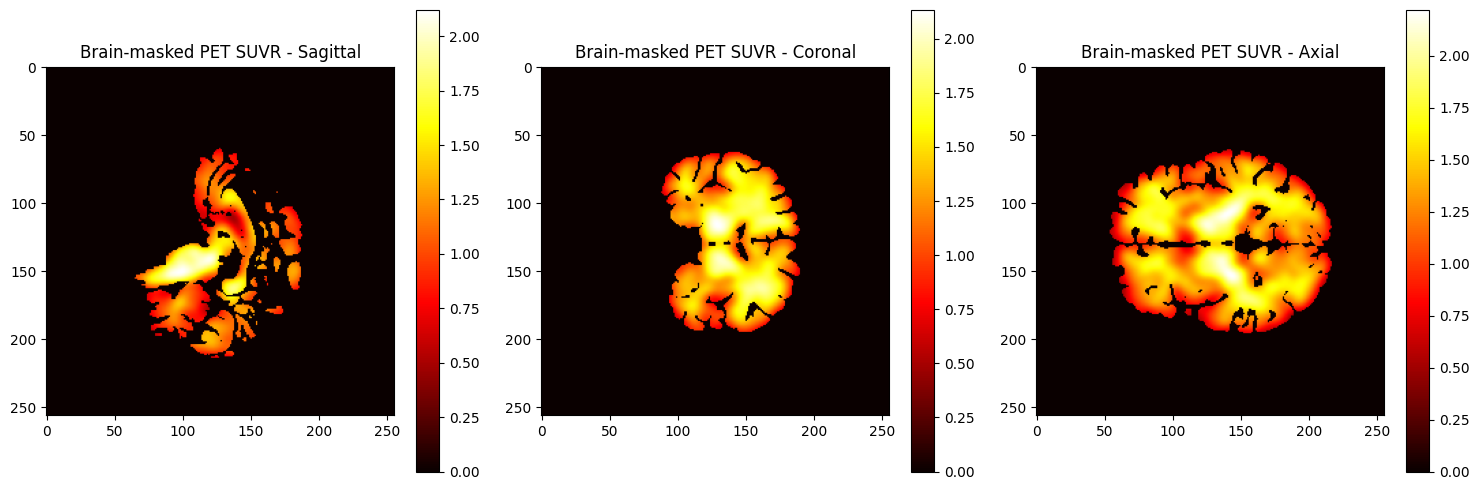

Mean SUVR in brain: 1.3132
Max SUVR in brain: 2.4080


In [3]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from utils.preprocessing import Utils
import os

from matplotlib import colormaps
print(list(colormaps))

def load_4dfp(filepath):
    """
    Load a 4dfp.img file and return the data array
    
    Args:
        filepath: Path to the .4dfp.img file
    
    Returns:
        numpy array containing the image data
    """
    # 4dfp is not directly supported by nibabel, so we need a custom approach
    # Option 1: Use nibabel's Analyze format reader (may work for some 4dfp files)
    try:
        img = nib.AnalyzeImage.load(filepath)
        data = img.get_fdata()
        return data, img.affine
    except:
        # Option 2: If specialized tools are available (dcm2niix or other WUSTL tools)
        # Convert to NIfTI first (shell command example)
        base_path = filepath.replace('.4dfp.img', '')
        output_nii = base_path + '.nii.gz'
        os.system(f"4dfp2nifti {base_path}")  # This command depends on having the proper tools installed
        
        # Then load with nibabel
        img = nib.load(output_nii)
        data = img.get_fdata()
        return data, img.affine

# Load the SUVR PET data (this is the processed image ready for analysis)
pet_file = "dataset/pup/OAS30003_PIB_d0756/OAS30003_PIB_PUPTIMECOURSE_d0756/pet_proc/OAS30003_PIB_d0756n_msum_SUVR_g8.4dfp.hdr"
pet_data, pet_affine = load_4dfp(pet_file)
print(pet_data.shape)

# Load the brain mask
mask_file = "dataset/pup/OAS30003_PIB_d0756/OAS30003_PIB_PUPTIMECOURSE_d0756/pet_proc/BrainMask.4dfp.hdr"
mask_data, mask_affine = load_4dfp(mask_file)
print(mask_data.shape)

# Apply binary mask to get brain-only PET data
# Convert mask to boolean
mask_bool = mask_data > 0
masked_pet_data = pet_data.copy()
masked_pet_data[~mask_bool] = 0  # Set non-brain voxels to zero

# Visualize a central slice of the masked PET data
def plot_central_slices(volume, title):
    """Plot central slices of a 3D volume in all three orientations"""
    # Get central slice indices
    x_mid = volume.shape[0] // 2
    y_mid = volume.shape[1] // 2
    z_mid = volume.shape[2] // 2
    
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.imshow(volume[x_mid, :, :], cmap='hot')
    plt.title(f"{title} - Sagittal")
    plt.colorbar()
    
    plt.subplot(1, 3, 2)
    plt.imshow(volume[:, y_mid, :], cmap='hot')
    plt.title(f"{title} - Coronal")
    plt.colorbar()
    
    plt.subplot(1, 3, 3)
    plt.imshow(volume[:, :, z_mid], cmap='hot')
    plt.title(f"{title} - Axial")
    plt.colorbar()
    
    plt.tight_layout()
    plt.show()

# Visualize the original and masked data
plot_central_slices(pet_data, "Original PET SUVR")
plot_central_slices(masked_pet_data, "Brain-masked PET SUVR")

# Extract values for analysis
brain_values = pet_data[mask_bool]
print(f"Mean SUVR in brain: {np.mean(brain_values):.4f}")
print(f"Max SUVR in brain: {np.max(brain_values):.4f}")